In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

print(train.shape)
print(test.shape)

(27455, 785)
(7172, 785)


In [5]:
X_train = train.drop("label", axis = 1).values
y_train = train["label"].values

X_test = test.drop("label", axis=1).values
y_test = test["label"].values

In [6]:
X_train = X_train.reshape(-1,28,28,1)/255.0
X_test = X_test.reshape(-1,28,28,1)/255.0

In [7]:
model = keras.Sequential([
    keras.Input(shape=(28,28,1)),

    keras.layers.Conv2D(32,(3,3),activation="relu"),
    keras.layers.MaxPooling2D((2,2)),

    keras.layers.Conv2D(63,(3,3),activation="relu"),
    keras.layers.MaxPooling2D((2,2)),

    keras.layers.Flatten(),
    keras.layers.Dense(128,activation="relu"),
    keras.layers.Dense(25,activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 63)          │          18,207 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 63)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1575)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         201,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 25)                  │           3,225 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 223,480 (872.97 KB)

 Trainable params: 223,480 (872.97 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [9]:
history = model.fit(
    X_train,y_train,
    epochs=10,
    validation_data=(X_test,y_test)
)

Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.7815 - loss: 0.7545 - val_accuracy: 0.8635 - val_loss: 0.4182
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9968 - loss: 0.0262 - val_accuracy: 0.8933 - val_loss: 0.3761
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9954 - loss: 0.0189 - val_accuracy: 0.8777 - val_loss: 0.4566
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9997 - loss: 0.0033 - val_accuracy: 0.8936 - val_loss: 0.3763
Epoch 5/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 1.0000 - loss: 5.2836e-04 - val_accuracy: 0.9016 - val_loss: 0.3964
Epoch 6/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9930 - loss: 0.0224 - val_accuracy: 0.8886 - val_loss: 0.4020
Epoch 7/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 1.0000 - loss: 7.4059e-04 - val_accuracy: 0.9020 - val_loss: 0.4186
Epoch 8/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 1.0000 - loss: 2.1747e-04 - val_

In [10]:
loss,accuracy = model.evaluate(X_test,y_test)
print("loss", loss)
print("accuracy", accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9007 - loss: 0.4495 
loss 0.44951388239860535
accuracy 0.9007250666618347


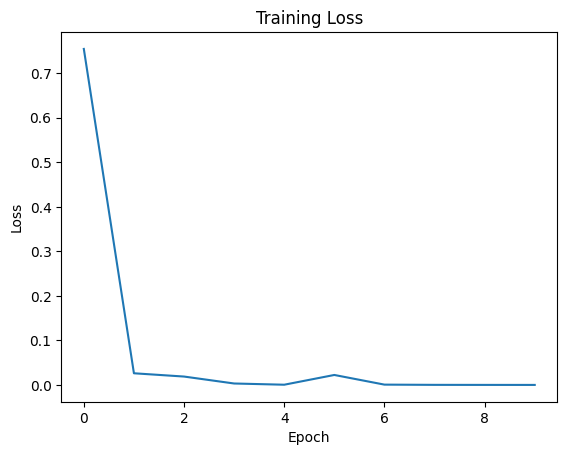

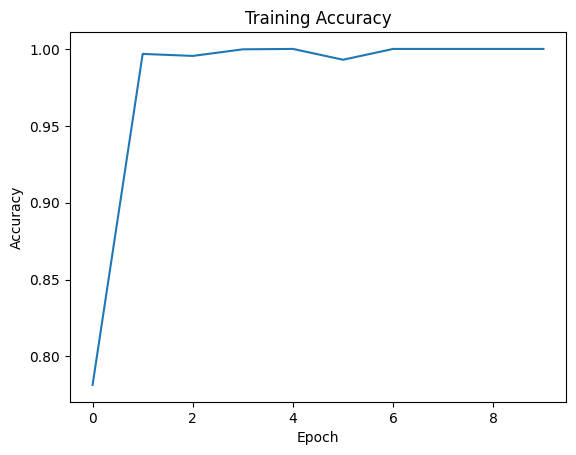

In [11]:
plt.plot(history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.plot(history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step


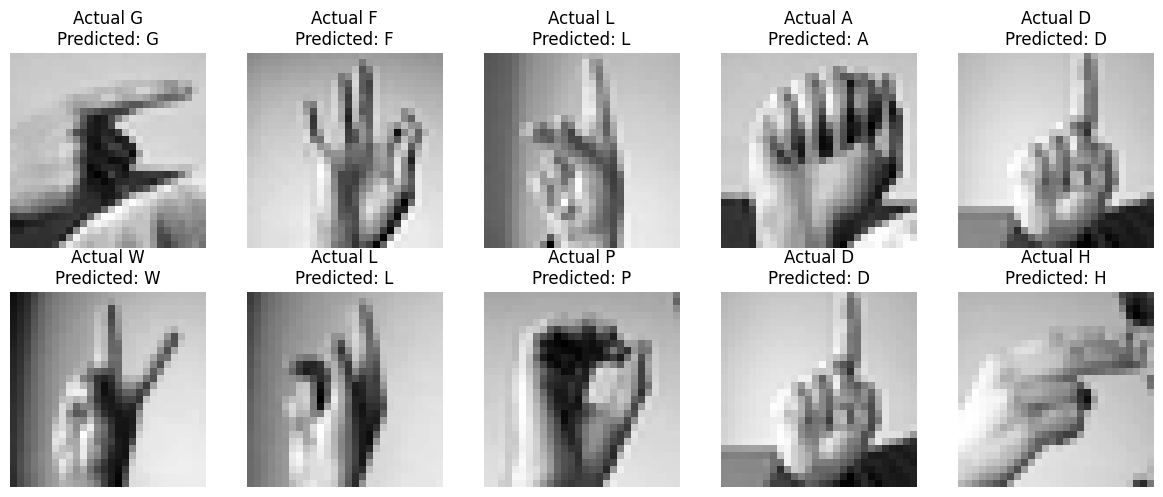

In [13]:
classes = list("ABCDEFGHIKLMNOPQRSTUVWXY")
predictions = model.predict(X_test[:10])

plt.figure(figsize=(12,5))

for i in range(10):
    plt.subplot(2,5,i+1)

    plt.imshow(X_test[i].reshape(28,28), cmap="gray")

    actual = classes[int(y_test[i])]
    predicted = classes[np.argmax(predictions[i])]

    plt.title(f"Actual {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()